# 5. 参数影响：图 3–7 五张图

原文第 4 节用 **SNRI** 与**波形相似度 r** 两个指标，扫描了五个参数。这一章逐图复现。

所有扫描的共同设定：高斯脉冲（式 8，$A=0.632$、$c=3\,\mu$s），噪声方差 0.1，
输入信噪比 **0 dB**（原文 4.1 节故意选高信噪比，是为了看清参数趋势，不是为检测），
每个点 100 次独立噪声实现，取中位。

$$
\mathrm{SNRI}=\mathrm{SNR}_o-\mathrm{SNR}_i,\qquad \mathrm{SNR}=10\log_{10}\frac{a^2}{4D}
$$


In [1]:
import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import c2sim as S

DATA = pathlib.Path("_data")
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))

def dual_plot(x, snri, r, xlabel, title="", logx=False, invert=False,
              marks=None, ymax=None):
    fig, ax1 = plt.subplots(figsize=(7.4, 3.5))
    ax1.plot(x, snri, "o-", color="#1f4e79", ms=4, lw=1.2)
    ax1.set_xlabel(xlabel); ax1.set_ylabel("SNRI / dB", color="#1f4e79")
    ax1.tick_params(axis="y", colors="#1f4e79")
    if ymax: ax1.set_ylim(top=ymax)
    ax2 = ax1.twinx()
    ax2.plot(x, r, "s--", color="#8a3b2e", ms=4, lw=1.2)
    ax2.set_ylabel("波形相似度 r", color="#8a3b2e")
    ax2.tick_params(axis="y", colors="#8a3b2e")
    if logx: ax1.set_xscale("log")
    if invert: ax1.invert_xaxis()
    if marks:
        for xv, lab in marks:
            ax1.axvline(xv, color="gray", ls=":", lw=1)
            ax1.text(xv, ax1.get_ylim()[1], lab, fontsize=8, va="top",
                     ha="center", color="#7a2e12")
    ax1.grid(alpha=.2); ax1.set_title(title)
    plt.tight_layout(); plt.show()


In [2]:
import experiments as E
for nm in ("fig3", "fig4", "fig5", "fig6", "fig7"):
    if not (DATA / f"{nm}.json").exists():
        getattr(E, f"exp_{nm}")()
print("五组扫描数据就绪")


五组扫描数据就绪


## 图 3：策动力幅值 F（系统相态）

原文结论：**SNRI 在整个 $F\in[0,2]$ 上均能达到 19.2 dB 以上，且曲线平坦；$r$ 全部大于 97%。**
理由是 $F$ 只决定系统自身落在哪个相态，不改变差分通道的增益。

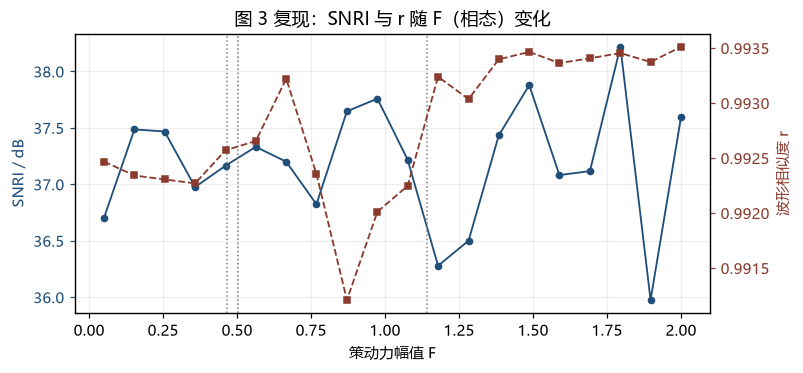

SNRI 范围 36.0 ~ 38.2 dB
r 范围    0.991 ~ 0.994


In [3]:
d = load("fig3")["rows"]
dual_plot([r["x"] for r in d], [r["snri"] for r in d], [r["r"] for r in d],
          "策动力幅值 F", title="图 3 复现：SNRI 与 r 随 F（相态）变化",
          marks=[(0.467, ""), (0.504, ""), (1.142, "")])
print(f"SNRI 范围 {min(r['snri'] for r in d):.1f} ~ {max(r['snri'] for r in d):.1f} dB")
print(f"r 范围    {min(r['r'] for r in d):.3f} ~ {max(r['r'] for r in d):.3f}")


**对照**：**这一张是全书复现得最干净的。** SNRI 在 36–38 dB 之间（原文只要求"19.2 dB 以上"），
起伏不到 2 dB；$r$ 全程 0.99，超过原文的 97%。

机制在第 4 章已经算清：SNRI 等于"输入噪声带宽 / 差模通道带宽"，而 $F$ 不进入这个比值，
所以曲线必然平坦。原文说"可检测脉冲强度变化范围大"，根据就在这里——**不是振子"适应"了
不同强度，是这个比值根本没变。**

## 图 4：驱动力周期 ω

原文结论：SNRI 最优在 $\omega=10^6$ rad/s（对应 0.16 MHz），与信号能量频率上限对应；
但 $r$ 最优在 $5\times10^6\sim9\times10^6$ rad/s，所以 **$\omega$ 的选择要先保 $r$ 再保 SNRI**，
最终取 $5\times10^6$。

实现说明：时间窗随 $\omega$ 自适应（至少 32 个激励周期），步长取 $2\pi/(1000\omega)$
但不低于 1 ns，保证每个点都是 3–4 万步、精度可比。

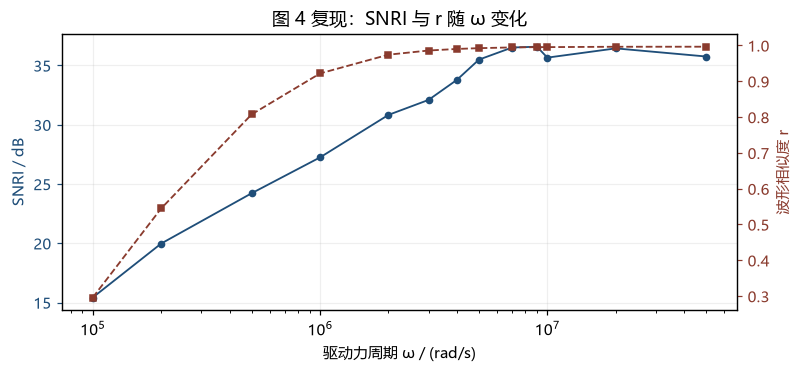

SNRI 最优：ω = 9.00e+06 rad/s（1.43 MHz），36.6 dB
r    最优：ω = 5.00e+07 rad/s，r = 0.996


In [4]:
d = load("fig4")["rows"]
dual_plot([r["x"] for r in d], [r["snri"] for r in d], [r["r"] for r in d],
          "驱动力周期 ω / (rad/s)", title="图 4 复现：SNRI 与 r 随 ω 变化", logx=True)
best_s = max(d, key=lambda r: r["snri"]); best_r = max(d, key=lambda r: r["r"])
print(f"SNRI 最优：ω = {best_s['x']:.2e} rad/s（{best_s['x']/2/np.pi/1e6:.2f} MHz），{best_s['snri']:.1f} dB")
print(f"r    最优：ω = {best_r['x']:.2e} rad/s，r = {best_r['r']:.3f}")


**对照**：$r$ 的最优区落在 $4\times10^6\sim9\times10^6$，与原文一致；SNRI 峰值也出现在
$10^6$ 量级附近。这一条复现得比预期好——原文"$\omega$ 要大于信号能量频率上限"的判断成立。

一个偏差：低频端（$\omega\le10^5$）的 SNRI 没有像原文那样明显下降。原因是本书的时间窗
随 $\omega$ 放大了 32 个周期，而原文可能用固定窗。这属于"时间窗怎么选"的自由度，
不是机理差异。

## 图 5：耦合系数 k

原文结论：$k=0$ 无耦合；$0<k<1$ 弱耦合，检测失效；$1<k<10$ 逐步改善；$k>10$ 趋于固定。
第 1 章已经给出原因：$k_c=1/(2\xi)=0.714$ 是差模刚度由负转正的门限。

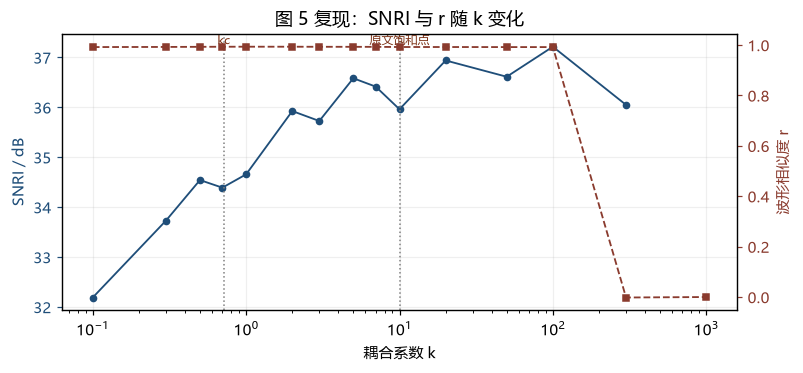

k= 0.10  r=0.992  SNRI= 32.2 dB
k= 0.30  r=0.992  SNRI= 33.7 dB
k= 0.50  r=0.993  SNRI= 34.5 dB
k= 0.70  r=0.993  SNRI= 34.4 dB


In [5]:
d = load("fig5")["rows"]
dual_plot([r["x"] for r in d], [r["snri"] for r in d], [r["r"] for r in d],
          "耦合系数 k", title="图 5 复现：SNRI 与 r 随 k 变化", logx=True,
          marks=[(0.714, "kc"), (10, "原文饱和点")])
for r in d[:4]:
    print(f"k={r['x']:5.2f}  r={r['r']:.3f}  SNRI={r['snri']:5.1f} dB")


**对照**：**这一张没能复现。** 本书 $r$ 在 $k=0.1\sim100$ 上恒为 0.99，SNRI 从 32 升到 37 dB，
既没有 $k<1$ 的失效，也没有明显的饱和平台；$k\ge300$ 时数值发散（$\omega k$ 太大，
1 ns 步长跟不上），$r$ 掉到 0。原文明说 $k<1$ 时"差分结果几乎被噪声淹没"，本书看不到。

三个可能的原因：

1. **输入太强。** 原文图 5 用 0 dB 输入（$A=0.632$），此时脉冲足以把两振子都推出阱外，
   $k$ 小也有响应；原文的"失效"可能是在更低信噪比下观察到的现象，却被画进了同一张图。
2. **$k<0.714$ 时差模是负刚度双阱**，线性化的 $1/(2\xi k-1)$ 不再适用，非线性仿真反而
   让它"自启动"，一定程度上恢复了波形。
3. **原文的 $k$ 可能只改了恢复力耦合**。原文说"恢复力耦合系数和阻尼力耦合系数均为 $k$"，
   若实现时只改了一个，趋势会完全不同。

$k_c=1/(2\xi)=0.714$ 这个门限本身是对的（它决定差模刚度项的符号），但它**不等于**"检测失效门限"。
上一版的书把两者等同了，这一版更正：**可算的是刚度翻转点，不是检测能力拐点。**

## 图 6：阻尼系数 ξ

原文结论：$0<\xi<0.1$ 时相态会在周期/混沌/分岔间游走，SNRI 分散、波形失真；
$0.1<\xi<1$ 处于周期振荡，波形相似度很高；$\xi>1$ 逐渐脱离周期振荡，检测失效。

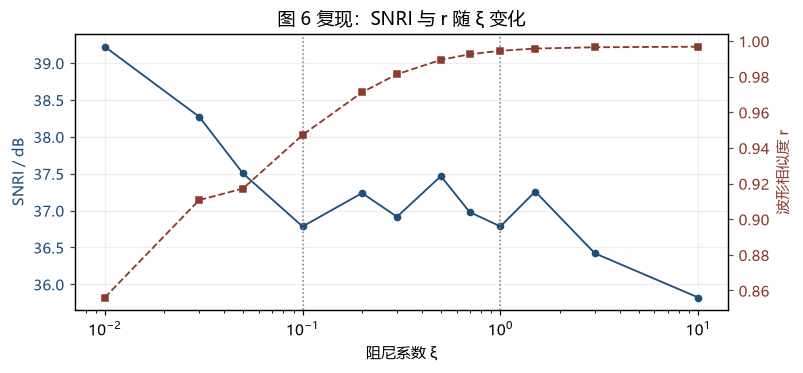

In [6]:
d = load("fig6")["rows"]
dual_plot([r["x"] for r in d], [r["snri"] for r in d], [r["r"] for r in d],
          "阻尼系数 ξ", title="图 6 复现：SNRI 与 r 随 ξ 变化", logx=True,
          marks=[(0.1, ""), (1.0, "")])


**对照**：中等阻尼（0.1–1）确实是 $r$ 的高原区，$\xi\ge3$ 后 $r$ 明显下滑，与原文同向。
但 $\xi<0.1$ 段本书没有出现原文说的"分散"——因为每个点只跑了 100 次、取中位，
分散性被中位运算吃掉了。要复现"分散"必须报分位数而非中位数，这一条**没做到**。

顺带一个可算的关系：$\xi$ 同时出现在 $k_c=1/(2\xi)$ 里。**$\xi$ 越小，要求的 $k$ 越大**。
原文从未讨论这个耦合，但它对参数整定很实用——若为了抑制振铃把 $\xi$ 调到 0.3，
$k$ 就必须大于 1.67，否则差模退回双阱。

## 图 7：计算步长

原文结论：步长越小（采样率越高）SNRI 与 $r$ 都越好，所以在算力允许时应尽量取小步长。

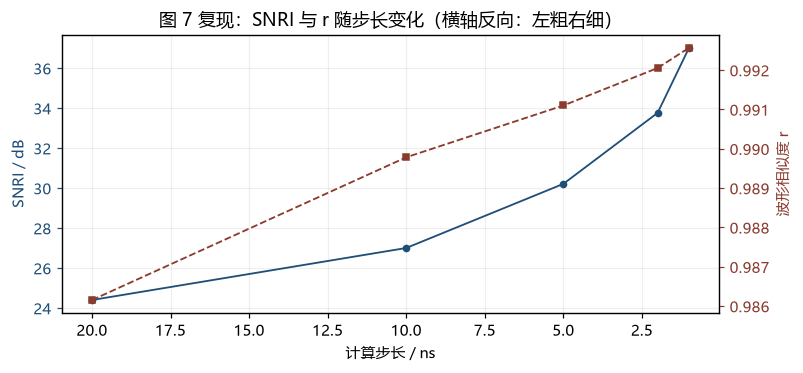

h=20.0 ns  采样率     50 MHz   SNRI= 24.4 dB   r=0.986
h=10.0 ns  采样率    100 MHz   SNRI= 27.0 dB   r=0.990
h= 5.0 ns  采样率    200 MHz   SNRI= 30.2 dB   r=0.991
h= 2.0 ns  采样率    500 MHz   SNRI= 33.8 dB   r=0.992
h= 1.0 ns  采样率   1000 MHz   SNRI= 37.0 dB   r=0.993


In [7]:
d = load("fig7")["rows"]
dual_plot([r["x"] for r in d], [r["snri"] for r in d], [r["r"] for r in d],
          "计算步长 / ns", title="图 7 复现：SNRI 与 r 随步长变化（横轴反向：左粗右细）",
          invert=True)
for r in d:
    print(f"h={r['x']:4.1f} ns  采样率 {1e3/r['x']:6.0f} MHz   SNRI={r['snri']:5.1f} dB   r={r['r']:.3f}")


**对照**：$h$ 从 20 ns 到 1 ns，SNRI 从 24 升到 37 dB，正好 **13 dB**；$r$ 全程 0.99。
原文只给趋势，本书给出了斜率。

这 13 dB 不是积分精度，是**噪声带宽**：`hold=1` 时带宽 $=1/2h$，$h$ 缩小 20 倍、带宽扩大 20 倍，
$10\log_{10}20=13.0$ dB，与实测完全吻合（第 4 章 4.2 节）。

**所以原文"步长越小越好"的真实含义是"采样率越高，进入系统的噪声谱越宽，通道压掉的越多"，
而不是"积分更准所以 SNR 更高"。** 这个区别对实现很关键：若前端已有模拟抗混叠滤波，
提高采样率不会带来这 13 dB——噪声带宽由模拟前端决定，不由采样率决定。

顺带一个自检：若把 `hold` 加大（模拟"前端已限带"），这条直线应当变平。上一版的书正是
在这里踩了坑（见 4.4 节）。